# Лабораторна робота №2
## Побудова та оцінювання регресійних моделей

**Мета:** виконати побудову, навчання та оцінювання регресійних моделей Linear Regression, Ridge Regression і Lasso Regression; дослідити вплив регуляризації на якість моделей та порівняти їх ефективність за метриками MAE, MSE, RMSE і R².

Використано набір даних з ЛР1 - **Telco Customer Churn**. Цільова змінна - `TotalCharges`, загальна сума, яку клієнт заплатив компанії за весь час. Це неперервне числове значення, тому задача - регресія.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Завантаження та підготовка даних

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Кількість записів:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Кількість записів: 7043
Кількість стовпців: 21


In [3]:
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Тип TotalCharges:", df["TotalCharges"].dtype)
print("Пропусків у TotalCharges:", df["TotalCharges"].isnull().sum())
df.loc[df["TotalCharges"].isnull(), ["tenure", "MonthlyCharges", "TotalCharges"]]

Тип TotalCharges: float64
Пропусків у TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [4]:
print("Кількість дублікатів:", df.duplicated().sum())
df = df.drop_duplicates()

df = df.dropna(subset=["TotalCharges"])
print("Кількість записів після очищення:", len(df))

Кількість дублікатів: 22
Кількість записів після очищення: 7010


Підготовка зроблена так само, як у ЛР1: видалено `customerID`, `TotalCharges` перетворено в число, видалено дублікати. Відмінність у тому, що тепер `TotalCharges` - це цільова змінна, а пропуски в цілі не заповнюють, бо модель має вчитися на реальних значеннях. Тому рядки з порожнім `TotalCharges` (нові клієнти з `tenure = 0`) видалено. Це можна зробити до поділу на вибірки, бо тут нічого не рахується з даних.

## 2. Початковий аналіз даних

In [5]:
print("Кількість об'єктів:", df.shape[0])
print("Кількість вхідних ознак:", df.shape[1] - 1)

Кількість об'єктів: 7010
Кількість вхідних ознак: 19


In [6]:
types_table = pd.DataFrame({
    "Ознака": df.columns,
    "Тип даних": df.dtypes.astype(str).values
})
types_table

,Ознака,Тип даних
0,gender,object
1,SeniorCitizen,int64
2,Partner,object
3,Dependents,object
4,tenure,int64
5,PhoneService,object
6,MultipleLines,object
7,InternetService,object
8,OnlineSecurity,object
9,OnlineBackup,object


In [7]:
missing_table = pd.DataFrame({
    "Кількість пропусків": df.isnull().sum(),
    "Частка, %": (df.isnull().mean() * 100).round(2)
})
missing_table

,Кількість пропусків,"Частка, %"
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0
OnlineBackup,0,0.0


In [8]:
df["TotalCharges"].describe().to_frame()

,TotalCharges
count,7010.000000
mean,2290.353388
std,2266.820832
min,18.800000
25%,408.312500
50%,1403.875000
75%,3807.837500
max,8684.800000


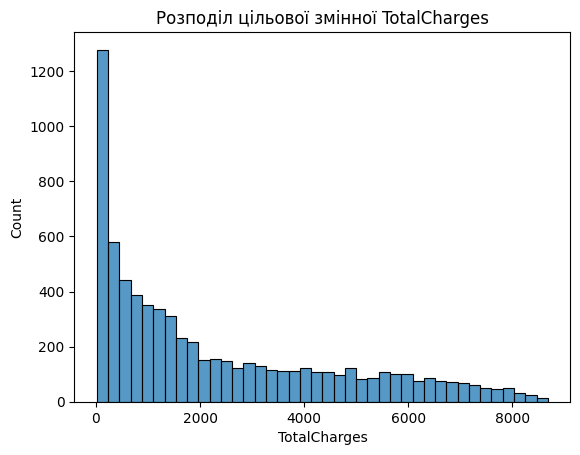

In [9]:
sns.histplot(df["TotalCharges"], bins=40)
plt.title("Розподіл цільової змінної TotalCharges")
plt.show()

In [10]:
correlations = df[["SeniorCitizen", "tenure", "MonthlyCharges"]].corrwith(df["TotalCharges"]).sort_values()
correlations.to_frame("Кореляція з TotalCharges")

,Кореляція з TotalCharges
SeniorCitizen,0.101642
MonthlyCharges,0.650540
tenure,0.825293


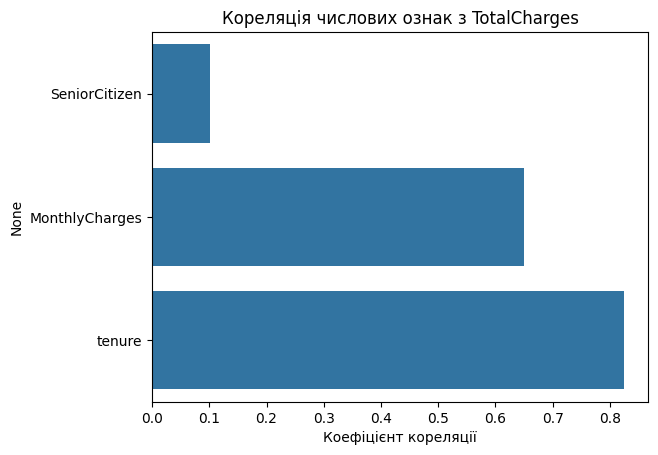

In [11]:
sns.barplot(x=correlations.values, y=correlations.index)
plt.title("Кореляція числових ознак з TotalCharges")
plt.xlabel("Коефіцієнт кореляції")
plt.show()

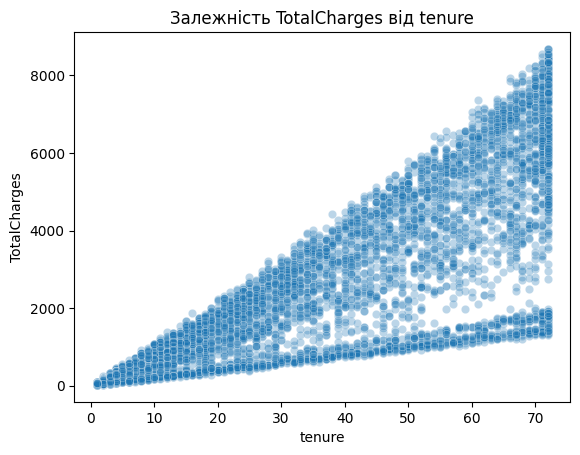

In [12]:
sns.scatterplot(x="tenure", y="TotalCharges", data=df, alpha=0.3)
plt.title("Залежність TotalCharges від tenure")
plt.show()

Після очищення в наборі 7010 об'єктів і 19 вхідних ознак: 16 категоріальних (текстових, разом з `Churn`) і 3 числові (`SeniorCitizen`, `tenure`, `MonthlyCharges`). Пропусків немає.

Цільова змінна `TotalCharges` лежить у межах від 18.8 до 8684.8, середнє 2290.35, медіана 1403.88. Середнє помітно більше за медіану, і на гістограмі видно, що розподіл скошений вправо: малих сум багато, великих мало.

Найсильніше з ціллю пов'язаний `tenure` (кореляція 0.83), потім `MonthlyCharges` (0.65), у `SeniorCitizen` зв'язок слабкий (0.10). На графіку `tenure` - `TotalCharges` точки розходяться «віялом» з променів: загальна сума приблизно дорівнює кількості місяців, помноженій на щомісячний платіж, і кожен промінь - це клієнти з близьким тарифом. Тобто залежність не чисто лінійна, а через добуток двох ознак, тому лінійна модель не зможе описати її ідеально.

## 3. Формування X та y

In [13]:
y = df["TotalCharges"]
X = df.drop(columns=["TotalCharges"])

categorical_columns = list(X.select_dtypes(include="object").columns)
numeric_columns = ["tenure", "MonthlyCharges"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
print("Категоріальні ознаки:", len(categorical_columns))
print(categorical_columns)
print("Числові ознаки для масштабування:", numeric_columns)

Розмір X: (7010, 19)
Розмір y: (7010,)
Категоріальні ознаки: 16
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
Числові ознаки для масштабування: ['tenure', 'MonthlyCharges']


Категоріальні ознаки будуть закодовані One-Hot після поділу на вибірки (пункт 5), щоб енкодер навчався тільки на навчальних даних. `Churn` тут не ціль, а звичайна категоріальна ознака. `SeniorCitizen` вже має значення 0/1, тому його не кодуємо і не масштабуємо.

## 4. Поділ на навчальну, валідаційну та тестову вибірки

In [14]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15 / 0.85, random_state=42
)

print("Навчальна вибірка:", X_train.shape, y_train.shape)
print("Валідаційна вибірка:", X_val.shape, y_val.shape)
print("Тестова вибірка:", X_test.shape, y_test.shape)

Навчальна вибірка: (4906, 19) (4906,)
Валідаційна вибірка: (1052, 19) (1052,)
Тестова вибірка: (1052, 19) (1052,)


Дані поділено у співвідношенні 70/15/15. На навчальній вибірці моделі вчаться, на валідаційній порівнюємо моделі й підбираємо alpha, а тестову використовуємо тільки один раз в кінці для чесної оцінки обраної моделі. Записів близько 7 тисяч, тому 15% (приблизно 1050 рядків) достатньо і для валідації, і для тесту. Спочатку відділено 15% на тест, потім з решти взято 15/85, щоб від усього набору це теж було 15%. `stratify` не використовується, бо ціль неперервна.

## 5. Масштабування та кодування ознак

In [15]:
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

print("Пропусків у X_train:", X_train.isnull().sum().sum())
print("Пропусків у X_val:", X_val.isnull().sum().sum())
print("Пропусків у X_test:", X_test.isnull().sum().sum())

Пропусків у X_train: 0
Пропусків у X_val: 0
Пропусків у X_test: 0


In [16]:
X_train[numeric_columns].describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges
mean,32.11,64.88
std,24.47,30.00
min,1.00,18.25
max,72.00,118.75


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train[numeric_columns])

X_train_scaled = pd.DataFrame(scaler.transform(X_train[numeric_columns]), columns=numeric_columns, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val[numeric_columns]), columns=numeric_columns, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test[numeric_columns]), columns=numeric_columns, index=X_test.index)

X_train_scaled.describe().loc[["mean", "std", "min", "max"]].round(2)

,tenure,MonthlyCharges
mean,0.00,-0.00
std,1.00,1.00
min,-1.27,-1.55
max,1.63,1.80


In [18]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_columns])

encoded_columns = encoder.get_feature_names_out(categorical_columns)

X_train_encoded = pd.DataFrame(encoder.transform(X_train[categorical_columns]), columns=encoded_columns, index=X_train.index)
X_val_encoded = pd.DataFrame(encoder.transform(X_val[categorical_columns]), columns=encoded_columns, index=X_val.index)
X_test_encoded = pd.DataFrame(encoder.transform(X_test[categorical_columns]), columns=encoded_columns, index=X_test.index)

print("Ознак після кодування:", len(encoded_columns))

Ознак після кодування: 43


In [19]:
X_train_ready = pd.concat([X_train_scaled, X_train[["SeniorCitizen"]], X_train_encoded], axis=1)
X_val_ready = pd.concat([X_val_scaled, X_val[["SeniorCitizen"]], X_val_encoded], axis=1)
X_test_ready = pd.concat([X_test_scaled, X_test[["SeniorCitizen"]], X_test_encoded], axis=1)

print("X_train_ready:", X_train_ready.shape)
print("X_val_ready:", X_val_ready.shape)
print("X_test_ready:", X_test_ready.shape)
print("Однакові колонки:", list(X_train_ready.columns) == list(X_val_ready.columns) == list(X_test_ready.columns))

X_train_ready: (4906, 46)
X_val_ready: (1052, 46)
X_test_ready: (1052, 46)
Однакові колонки: True


Пропусків в ознаках після очищення немає, тому імпутер не потрібен. Масштабування потрібне для `tenure` і `MonthlyCharges`, бо вони мають різні діапазони, а Ridge і Lasso штрафують коефіцієнти: без масштабування штраф діяв би на ознаки нерівномірно, і коефіцієнти не можна було б порівнювати між собою. Обрано `StandardScaler`, параметри (середнє і std) пораховані тільки по `X_train` і без перенавчання застосовані до валідаційної і тестової вибірок. Енкодер так само навчений тільки на `X_train`.

## 6. Linear Regression

In [20]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_ready, y_train)

print("Вільний член:", round(linear_model.intercept_, 3))
print("Кількість коефіцієнтів:", len(linear_model.coef_))

Вільний член: 2280.638
Кількість коефіцієнтів: 46


## 7. Оцінювання Linear Regression

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_train_pred = linear_model.predict(X_train_ready)
y_val_pred = linear_model.predict(X_val_ready)

results_linear = pd.DataFrame({
    "Метрика": ["MAE", "MSE", "RMSE", "R²"],
    "Навчальна": [
        mean_absolute_error(y_train, y_train_pred),
        mean_squared_error(y_train, y_train_pred),
        np.sqrt(mean_squared_error(y_train, y_train_pred)),
        r2_score(y_train, y_train_pred)
    ],
    "Валідаційна": [
        mean_absolute_error(y_val, y_val_pred),
        mean_squared_error(y_val, y_val_pred),
        np.sqrt(mean_squared_error(y_val, y_val_pred)),
        r2_score(y_val, y_val_pred)
    ]
})
results_linear.round(3)

,Метрика,Навчальна,Валідаційна
0,MAE,550.552,565.967
1,MSE,469856.363,485187.239
2,RMSE,685.461,696.554
3,R²,0.907,0.910


На навчальній вибірці MAE = 550.55, RMSE = 685.46, R² = 0.907, на валідаційній MAE = 565.97, RMSE = 696.55, R² = 0.910. Модель пояснює приблизно 91% варіативності `TotalCharges`. Середня помилка близько 566 при середньому значенні цілі 2290, тобто похибка відчутна. Результати на train і val майже однакові, отже ознак перенавчання немає.

## 8. Ridge Regression

In [22]:
from sklearn.linear_model import Ridge

alphas = [0.01, 0.1, 1, 10, 100]
ridge_results = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_ready, y_train)
    y_pred = model.predict(X_val_ready)
    mse = mean_squared_error(y_val, y_pred)
    ridge_results.append({
        "alpha": alpha,
        "MAE": mean_absolute_error(y_val, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_val, y_pred)
    })

ridge_results = pd.DataFrame(ridge_results)
best_ridge_alpha = ridge_results.loc[ridge_results["RMSE"].idxmin(), "alpha"]

print("Найкраще alpha для Ridge за RMSE:", best_ridge_alpha)
ridge_results.round(3)

Найкраще alpha для Ridge за RMSE: 0.1


,alpha,MAE,MSE,RMSE,R²
0,0.01,565.966,485186.982,696.554,0.910
1,0.10,565.959,485185.104,696.552,0.910
2,1.00,565.916,485192.591,696.558,0.910
3,10.00,566.090,485535.068,696.803,0.910
4,100.00,569.376,490324.236,700.232,0.909


Для alpha від 0.01 до 10 метрики майже не змінюються (RMSE від 696.55 до 696.80, R² = 0.910). Найменший RMSE при alpha = 0.1, але різниця з іншими значеннями соті частки. При alpha = 100 модель стає трохи гіршою (RMSE 700.23, R² 0.909), бо сильний штраф уже зменшує корисні коефіцієнти. Регуляризація тут мало що змінює, тому що модель і так не перенавчена: навчальних об'єктів 4906, а ознак лише 46.

## 9. Lasso Regression

In [23]:
from sklearn.linear_model import Lasso

lasso_results = []

for alpha in alphas:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_ready, y_train)
    y_pred = model.predict(X_val_ready)
    mse = mean_squared_error(y_val, y_pred)
    lasso_results.append({
        "alpha": alpha,
        "MAE": mean_absolute_error(y_val, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_val, y_pred),
        "Нульових коефіцієнтів": np.sum(model.coef_ == 0)
    })

lasso_results = pd.DataFrame(lasso_results)
best_lasso_alpha = lasso_results.loc[lasso_results["RMSE"].idxmin(), "alpha"]

print("Найкраще alpha для Lasso за RMSE:", best_lasso_alpha)
lasso_results.round(3)

Найкраще alpha для Lasso за RMSE: 1.0


,alpha,MAE,MSE,RMSE,R²,Нульових коефіцієнтів
0,0.01,565.974,485189.656,696.556,0.910,6
1,0.10,565.927,485154.541,696.530,0.910,15
2,1.00,565.508,484991.426,696.413,0.910,16
3,10.00,567.056,490429.020,700.306,0.909,25
4,100.00,599.002,565407.392,751.936,0.895,44


Зі збільшенням alpha Lasso обнуляє все більше коефіцієнтів: 6 при alpha = 0.01, 15 при 0.1, 16 при 1, 25 при 10 і 44 з 46 при alpha = 100. Найкращий результат на валідації при alpha = 1: RMSE 696.41, MAE 565.51, R² 0.910. Це навіть трохи краще, ніж у Linear Regression, хоча 16 ознак модель не використовує. При alpha = 100 у моделі залишаються лише 2 ознаки, і якість помітно падає (RMSE 751.94, R² 0.895). Це вже недонавчання через надто сильну регуляризацію.

## 10. Вибір моделі та оцінювання на тестовій вибірці

In [24]:
comparison = {
    "Linear Regression": results_linear.loc[results_linear["Метрика"] == "RMSE", "Валідаційна"].iloc[0],
    "Ridge Regression": ridge_results["RMSE"].min(),
    "Lasso Regression": lasso_results["RMSE"].min()
}

comparison_table = pd.DataFrame({
    "Модель": list(comparison.keys()),
    "RMSE на валідації": list(comparison.values())
})
comparison_table.round(3)

,Модель,RMSE на валідації
0,Linear Regression,696.554
1,Ridge Regression,696.552
2,Lasso Regression,696.413


In [25]:
best_name = min(comparison, key=comparison.get)

if best_name == "Linear Regression":
    final_model = LinearRegression()
elif best_name == "Ridge Regression":
    final_model = Ridge(alpha=best_ridge_alpha)
else:
    final_model = Lasso(alpha=best_lasso_alpha, max_iter=10000)

X_train_full = pd.concat([X_train_ready, X_val_ready])
y_train_full = pd.concat([y_train, y_val])

final_model.fit(X_train_full, y_train_full)
y_test_pred = final_model.predict(X_test_ready)

test_mse = mean_squared_error(y_test, y_test_pred)

print("Обрана модель:", best_name)
print("Розмір train + val:", X_train_full.shape)
print("MAE:", round(mean_absolute_error(y_test, y_test_pred), 3))
print("MSE:", round(test_mse, 3))
print("RMSE:", round(np.sqrt(test_mse), 3))
print("R²:", round(r2_score(y_test, y_test_pred), 3))

Обрана модель: Lasso Regression
Розмір train + val: (5958, 46)
MAE: 557.417
MSE: 466379.874
RMSE: 682.92
R²: 0.909


За RMSE на валідації найкращою виявилась Lasso Regression з alpha = 1 (696.41 проти 696.55 у Linear і Ridge). Її перенавчено на об'єднаних навчальній і валідаційній вибірках (5958 записів) і один раз оцінено на тестовій: MAE = 557.42, MSE = 466379.87, RMSE = 682.92, R² = 0.909. Результат на тесті дуже близький до валідаційного, отже модель добре працює на нових даних. Варто чесно сказати, що різниця між трьома моделями на валідації менша за 1 в RMSE, тобто за точністю вони практично однакові.

## 11. Аналіз коефіцієнтів моделей

In [26]:
ridge_model = Ridge(alpha=best_ridge_alpha)
ridge_model.fit(X_train_ready, y_train)

lasso_model = Lasso(alpha=best_lasso_alpha, max_iter=10000)
lasso_model.fit(X_train_ready, y_train)

coef_table = pd.DataFrame({
    "Ознака": X_train_ready.columns,
    "Linear": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_
})
coef_table["Макс. |коеф.|"] = coef_table[["Linear", "Ridge", "Lasso"]].abs().max(axis=1)

coef_table.sort_values("Макс. |коеф.|", ascending=False).head(15).round(3)

,Ознака,Linear,Ridge,Lasso,Макс. |коеф.|
0,tenure,1485.374,1485.288,1483.333,1485.374
1,MonthlyCharges,1044.499,1028.886,1051.283,1051.283
43,PaymentMethod_Mailed check,170.865,170.827,184.819,184.819
37,Contract_Two year,-138.744,-138.692,-184.485,184.485
22,OnlineBackup_Yes,135.910,138.656,122.338,138.656
20,OnlineBackup_No,-126.377,-126.269,-135.025,135.025
44,Churn_No,69.150,69.164,132.406,132.406
28,TechSupport_Yes,107.203,109.936,122.128,122.128
25,DeviceProtection_Yes,98.103,100.836,111.592,111.592
19,OnlineSecurity_Yes,104.377,107.108,101.463,107.108


In [27]:
coef_summary = pd.DataFrame({
    "Середній |коеф.|": coef_table[["Linear", "Ridge", "Lasso"]].abs().mean(),
    "Максимальний |коеф.|": coef_table[["Linear", "Ridge", "Lasso"]].abs().max(),
    "Нульових коефіцієнтів": (coef_table[["Linear", "Ridge", "Lasso"]] == 0).sum()
})
coef_summary.round(3)

,Середній |коеф.|,Максимальний |коеф.|,Нульових коефіцієнтів
Linear,101.946,1485.374,0
Ridge,102.610,1485.288,0
Lasso,95.046,1483.333,16


In [28]:
zero_features = coef_table.loc[coef_table["Lasso"] == 0, "Ознака"]
print("Коефіцієнтів Lasso, зменшених до нуля:", len(zero_features), "з", len(coef_table))
print(list(zero_features))

Коефіцієнтів Lasso, зменшених до нуля: 16 з 46
['SeniorCitizen', 'Partner_Yes', 'Dependents_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service', 'Contract_One year', 'PaperlessBilling_Yes']


Найбільший вплив на прогноз мають `tenure` (коефіцієнт близько 1485) і `MonthlyCharges` (1029-1051). Це логічно: загальна сума залежить від того, скільки місяців клієнт платить і скільки платить щомісяця. Обидва коефіцієнти додатні, бо більші значення цих ознак збільшують `TotalCharges`. Серед категоріальних ознак найсильніше впливають `PaymentMethod_Mailed check` (+171...+185), `Contract_Two year` (-139...-184), підключені послуги `OnlineBackup`, `TechSupport`, `DeviceProtection`, `OnlineSecurity` (значення Yes збільшує прогноз) і `Churn_No`.

Ridge з alpha = 0.1 змінив коефіцієнти дуже мало, на одиниці. Середній модуль коефіцієнтів навіть трохи зріс (101.95 у Linear і 102.61 у Ridge), бо Ridge рівномірніше розподіляє вагу між схожими ознаками. Наприклад, `OnlineSecurity_Yes` змінився з 104.38 на 107.11.

Lasso обнулив 16 коефіцієнтів з 46, і середній модуль зменшився до 95.05. Обнулені передусім ознаки, які дублюють одна одну: усі стовпці «No internet service» і `InternetService_*`. Значення «No internet service» в шести колонках повторює `InternetService_No`, тому достатньо однієї з них. Також обнулені слабкі ознаки: `SeniorCitizen`, `Partner_Yes`, `Dependents_Yes`, `PaperlessBilling_Yes`, `Contract_One year`. Натомість Lasso збільшив вагу частини ознак, що залишились (`Churn_No` з 69 до 132, `Contract_Two year` з -139 до -184).

Варто враховувати, що One-Hot створює стовпці для всіх категорій, і вони лінійно залежні між собою. Через це окремі коефіцієнти категорій у Linear Regression не єдині, і порівнювати їх треба обережно. Ridge і Lasso якраз роблять їх стійкішими.

## 12. Порівняння трьох моделей

In [29]:
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

results = []

for name, model in models.items():
    train_pred = model.predict(X_train_ready)
    val_pred = model.predict(X_val_ready)
    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)
    results.append({
        "Модель": name,
        "MAE train": mean_absolute_error(y_train, train_pred),
        "MAE val": mean_absolute_error(y_val, val_pred),
        "MSE train": train_mse,
        "MSE val": val_mse,
        "RMSE train": np.sqrt(train_mse),
        "RMSE val": np.sqrt(val_mse),
        "R² train": r2_score(y_train, train_pred),
        "R² val": r2_score(y_val, val_pred)
    })

results_table = pd.DataFrame(results)
results_table.round(3)

,Модель,MAE train,MAE val,MSE train,MSE val,RMSE train,RMSE val,R² train,R² val
0,Linear Regression,550.552,565.967,469856.363,485187.239,685.461,696.554,0.907,0.91
1,Ridge Regression,550.555,565.959,469856.650,485185.104,685.461,696.552,0.907,0.91
2,Lasso Regression,550.491,565.508,469981.257,484991.426,685.552,696.413,0.907,0.91


## 13. Графічне представлення результатів

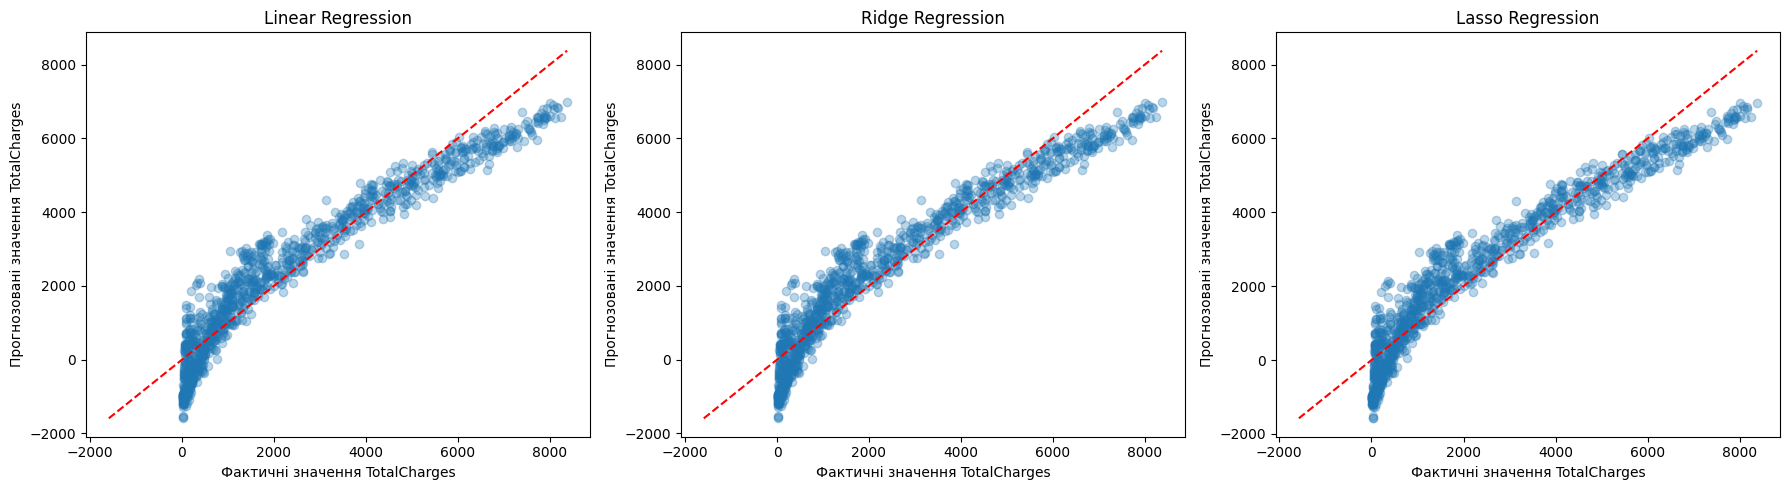

In [30]:
predictions = {
    "Linear Regression": linear_model.predict(X_val_ready),
    "Ridge Regression": ridge_model.predict(X_val_ready),
    "Lasso Regression": lasso_model.predict(X_val_ready)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_val, pred, alpha=0.3)
    min_value = min(y_val.min(), pred.min())
    max_value = max(y_val.max(), pred.max())
    ax.plot([min_value, max_value], [min_value, max_value], linestyle="--", color="red")
    ax.set_title(name)
    ax.set_xlabel("Фактичні значення TotalCharges")
    ax.set_ylabel("Прогнозовані значення TotalCharges")

plt.tight_layout()
plt.show()

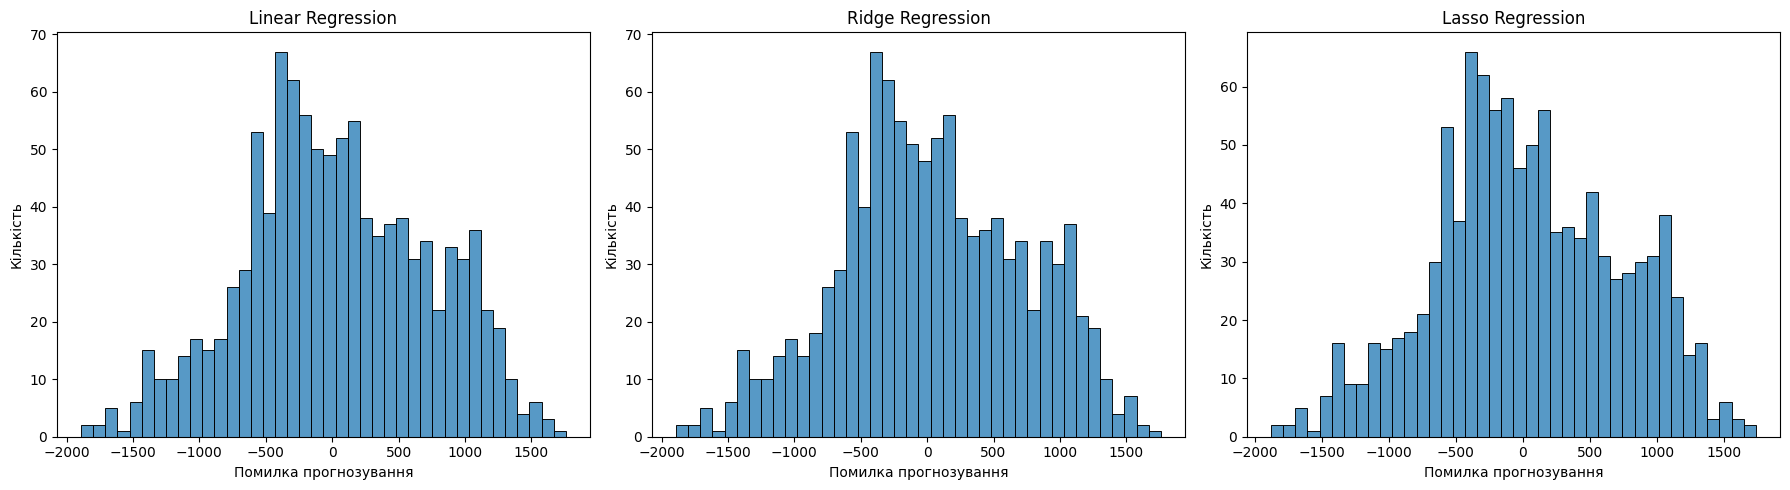

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    sns.histplot(y_val - pred, bins=40, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Помилка прогнозування")
    ax.set_ylabel("Кількість")

plt.tight_layout()
plt.show()

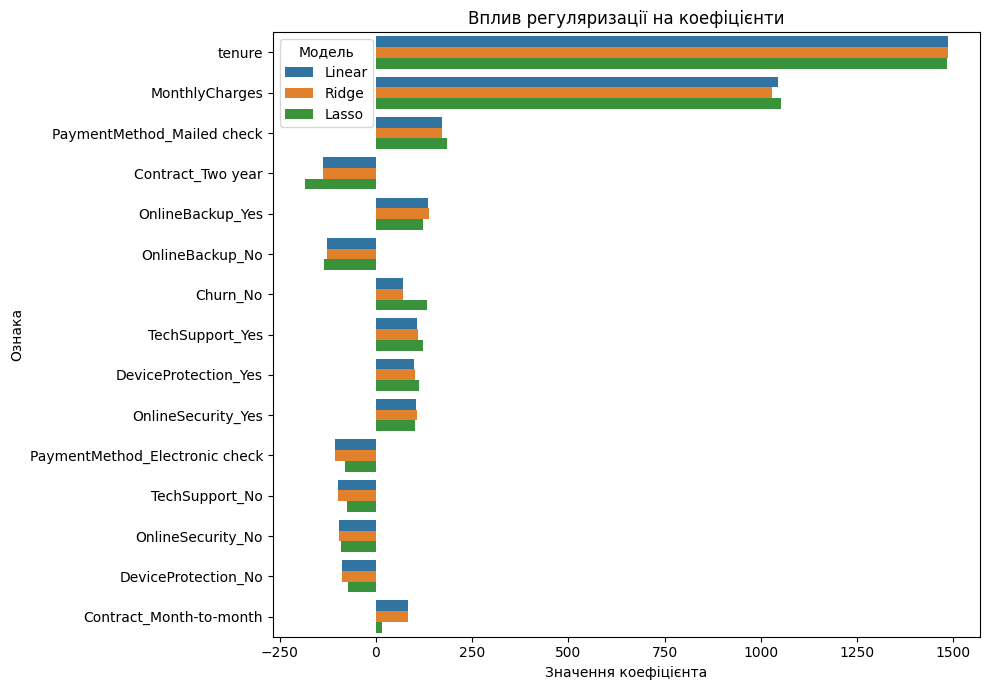

In [32]:
top_features = coef_table.sort_values("Макс. |коеф.|", ascending=False).head(15)

plot_data = top_features.melt(
    id_vars="Ознака",
    value_vars=["Linear", "Ridge", "Lasso"],
    var_name="Модель",
    value_name="Коефіцієнт"
)

plt.figure(figsize=(10, 7))
sns.barplot(data=plot_data, x="Коефіцієнт", y="Ознака", hue="Модель")
plt.title("Вплив регуляризації на коефіцієнти")
plt.xlabel("Значення коефіцієнта")
plt.tight_layout()
plt.show()

На графіках «факт - прогноз» точки в середньому лежать уздовж червоної лінії, але утворюють вигнуту криву. Для клієнтів з малою сумою модель часто прогнозує від'ємні значення (аж до приблизно -1600), а для найбільших сум (понад 7000) занижує прогноз. Це наслідок того, що справжня залежність йде через добуток `tenure` і `MonthlyCharges`, а лінійна модель його не враховує. Помилки розподілені навколо нуля, більшість лежить у межах ±1500. Графіки всіх трьох моделей майже не відрізняються, що збігається з метриками. На останньому графіку видно, що регуляризація майже не чіпає головні ознаки `tenure` і `MonthlyCharges`, а помітно змінює лише коефіцієнти категоріальних ознак, особливо в Lasso.

## 14. Аналіз перенавчання та недонавчання

Ознак перенавчання немає в жодній моделі: показники на навчальній і валідаційній вибірках майже однакові (R² 0.907 і 0.910, RMSE 685 і 697, різниця близько 1.6%). На валідації R² навіть трохи вищий. Модель не «запам'ятовує» навчальні дані, бо ознак (46) набагато менше, ніж об'єктів (4906).

Водночас є ознаки недонавчання. Помилки систематичні: від'ємні прогнози для малих сум і заниження для великих. Ця проблема однакова на train і val, тобто модель просто надто проста для такої залежності. Лінійні моделі не можуть описати добуток двох ознак. Сильна регуляризація ще посилює недонавчання: Lasso з alpha = 100 має R² лише 0.895, Ridge з alpha = 100 - 0.909.

## 15. Вибір найбільш придатної моделі

Найбільш придатною для цього набору даних обрано **Lasso Regression з alpha = 1**:
- точність: найменший RMSE (696.41) і MAE (565.51) на валідації; на тесті RMSE 682.92, R² 0.909;
- узагальнювальна здатність: результати на train, val і test дуже близькі, перенавчання немає;
- складність: модель використовує 30 ознак з 46, тобто вона простіша за Linear і Ridge при тій самій точності.

Різниця в точності між трьома моделями дуже мала, тому на практиці підійшла б будь-яка з них. Lasso обрано саме тому, що при однаковій точності вона простіша і сама прибрала зайві й дубльовані ознаки.

## 16. Висновки

- **Порівняння моделей.** Linear Regression, Ridge і Lasso дали практично однакову якість: R² близько 0.91 на валідації, RMSE близько 696, MAE близько 566. Найкращою за валідацією стала Lasso з alpha = 1, на тестовій вибірці вона показала MAE 557.42, RMSE 682.92, R² 0.909.
- **Вплив регуляризації.** Слабка і помірна регуляризація (alpha до 10) на якість майже не вплинула, бо модель не перенавчена. Ridge лише трохи перерозподілив коефіцієнти між схожими ознаками. Lasso обнулив 16 коефіцієнтів (дубльовані One-Hot стовпці «No internet service» і слабкі ознаки) без втрати точності. Сильна регуляризація (alpha = 100) призвела до недонавчання, особливо в Lasso, яка залишила лише 2 ознаки.
- **Linear Regression:** проста, швидка, не потребує підбору параметрів. Недолік: з лінійно залежними One-Hot ознаками її коефіцієнти нестійкі й неоднозначні.
- **Ridge Regression:** стійкіші коефіцієнти при мультиколінеарності. Але тут вона не дала виграшу в точності і залишає всі 46 ознак.
- **Lasso Regression:** сама відбирає ознаки, і модель виходить простішою та легшою для пояснення. Недоліки: потрібно підбирати alpha, а при великому alpha вона викидає й корисні ознаки; із групи схожих ознак залишає одну досить випадково.
- **Спільний недолік** усіх трьох моделей для цієї задачі - вони лінійні. `TotalCharges` залежить від добутку `tenure` і `MonthlyCharges`, тому моделі систематично помиляються на малих і великих сумах і навіть дають від'ємні прогнози.